In [28]:
reset

Once deleted, variables cannot be recovered. Proceed (y/[n])? t
Once deleted, variables cannot be recovered. Proceed (y/[n])? y


In [29]:
import pandas as pd
from sqlalchemy import create_engine
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from scipy.stats import zscore
from scipy.stats import pearsonr
from scipy.stats import spearmanr
from scipy.stats import linregress
import matplotlib.patheffects as path_effects
from scipy.stats import rankdata
from adjustText import adjust_text

In [30]:
plt.rcParams['font.size'] = 24

## define helper functions

In [31]:
def shooting_percentage(x):
    return (x == "Made").mean()  # assumes "Made" / "Missed" strings

def make_percentile(x):
    return (x - min(x)) / (max(x) - min(x))

def build_shooting_summary(df, shot_cutoff):
    """
    Build summary statistics and consistency metrics for a season dataframe.

    Parameters
    ----------
    df : pandas.DataFrame
        Shot-level dataframe.
    shot_cutoff : int
        Minimum number of shots for inclusion.

    Returns
    -------
    pandas.DataFrame
        Clean season-level summary with consistency/command metrics.
    """

    # ---- Aggregate base stats ----
    summary = (
        df.groupby('personid').agg(
            playernamei=('playernamei', 'first'),
            num_shots=('ftid', 'count'),
            release_v_mag_mean=('release_v_mag', 'mean'),
            release_v_mag_std=('release_v_mag', 'std'),
            launch_angle_mean=('launch_angle', 'mean'),
            launch_angle_std=('launch_angle', 'std'),
            distance_mean=('distance', 'mean'),
            distance_std=('distance', 'std'),
            dist_from_sweet_mean=('dist_from_sweet', 'mean'),
            dist_from_sweet_std=('dist_from_sweet', 'std'),
            shooting_percentage=('shotresult', shooting_percentage),  # pass function
        )
        .reset_index()
    )

    # ---- Shot cutoff ----
    summary = summary[summary['num_shots'] >= shot_cutoff].reset_index(drop=True)

    # ---- Command metric ----
    mu = summary['dist_from_sweet_mean']
    sigma = summary['dist_from_sweet_std']
    summary['command'] = 1 / (1 + np.sqrt(mu**2 + sigma**2))

    # Percentile of command
    summary['command_percentile'] = (
        summary['command'] - summary['command'].min()
    ) / (summary['command'].max() - summary['command'].min())

    # ---- Inconsistency metrics ----
    inconsistency_metrics = ['launch_angle_std', 'release_v_mag_std', 'distance_std']

    for col in inconsistency_metrics:
        zcol = f'{col}_z'
        summary[zcol] = (summary[col] - summary[col].mean()) / summary[col].std()

    # Refined inconsistency (angle + velocity only)
    refined_cols = ['launch_angle_std', 'release_v_mag_std']
    summary['inconsistency_score_refined'] = summary[[f'{c}_z' for c in refined_cols]].sum(axis=1)

    # ---- Final selected/renamed output ----
    out = summary[[
        'personid', 'playernamei', 'num_shots',
        'release_v_mag_mean', 'release_v_mag_std',
        'launch_angle_mean', 'launch_angle_std',
        'dist_from_sweet_mean', 'dist_from_sweet_std',
        'shooting_percentage',
        'command', 'command_percentile',
        'launch_angle_std_z', 'release_v_mag_std_z', 'distance_std_z',
        'inconsistency_score_refined'
    ]].rename(columns={
        'release_v_mag_mean': 'launch_velo_mean',
        'release_v_mag_std': 'launch_velo_std',
        'launch_angle_std_z': 'launch_angle_inconsistency_zscore',
        'release_v_mag_std_z': 'launch_velo_inconsistency_zscore',
        'distance_std_z': 'launch_distance_inconsistency_zscore',
        'inconsistency_score_refined': 'inconsistency_score'
    })
    
    # ---- inconsistency and consistency components normalized -----
    out['launch_velo_consistency_normalized'] = 1 - make_percentile(out['launch_velo_inconsistency_zscore'])
    out['launch_angle_consistency_normalized'] = 1 - make_percentile(out['launch_angle_inconsistency_zscore'])
    out['launch_distance_consistency_normalized'] = 1 - make_percentile(out['launch_distance_inconsistency_zscore'])

    # ---- Percentiles for inconsistency and consistency ----
    out['inconsistency_score_percentile'] = (
        out['inconsistency_score'] - out['inconsistency_score'].min()
    ) / (out['inconsistency_score'].max() - out['inconsistency_score'].min())

    out['consistency_score_percentile'] = 1.0 - out['inconsistency_score_percentile']

    return out

def fit_line(x, y):
    """
    Fit a straight line y = m*x + b to data.
    
    Parameters
    ----------
    x : array-like
        Independent variable.
    y : array-like
        Dependent variable.
    plot : bool, optional
        If True, plot the data and the fitted line. Default is True.
    
    Returns
    -------
    slope : float
        Slope of the fitted line.
    intercept : float
        Intercept of the fitted line.
    """
    x = np.array(x)
    y = np.array(y)
    
    # Fit line using numpy.polyfit
    slope, intercept = np.polyfit(x, y, 1)
    return slope, intercept

# grab data here

In [37]:
print(f"df_name_id rows: {len(df_name_id)}")
print(f"df_metrics_id rows: {len(df_metrics_id)}")
print(f"merged rows: {len(df)}")

df_name_id rows: 139451
df_metrics_id rows: 101679
merged rows: 101679


In [39]:
df["timeactual"] = pd.to_datetime(df["timeactual"], utc=True)
cutoff = pd.Timestamp("2024-08-01", tz="UTC") #seperate the 23-24 and 24-25 season
df = df[df["timeactual"] >= cutoff].reset_index(drop=True)

In [41]:
print(f"2024-2025 data: {len(df)}")

2024-2025 data: 49562


In [42]:
df['release_v_mag'] = df['release_v_mag'] * 3600/5280

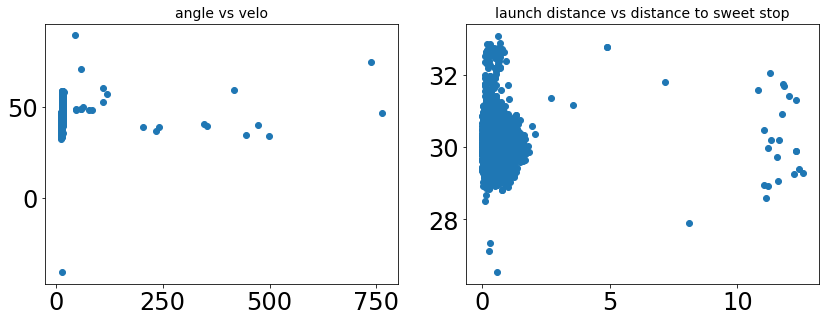

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 1 row, 2 columns

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()


In [44]:
k = 4

In [45]:
mean = df["dist_from_sweet"].mean(skipna=True)
stdev = df["dist_from_sweet"].std(skipna=True)

mask = (df["dist_from_sweet"] >= mean - k*stdev) & (df["dist_from_sweet"] <= mean + k*stdev)
df = df[mask].copy()

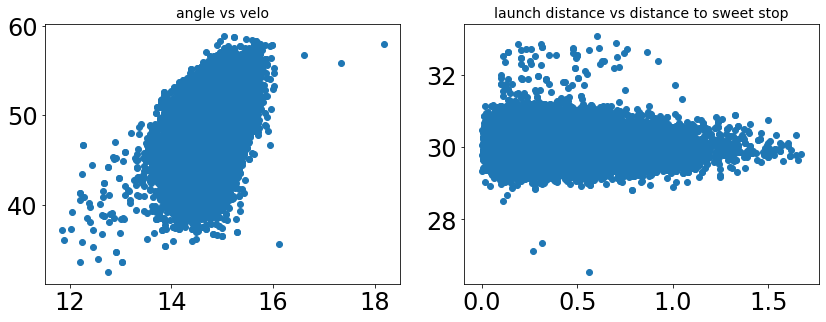

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 1 row, 2 columns

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()

In [47]:
mean = df["distance"].mean(skipna=True)
stdev = df["distance"].std(skipna=True)

mask = (df["distance"] >= mean - k*stdev) & (df["distance"] <= mean + k*stdev)
df = df[mask].copy()

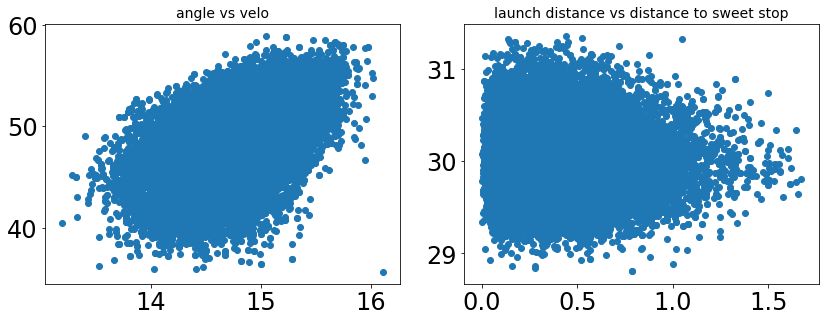

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 1 row, 2 columns

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()

In [49]:
mean = df["release_v_mag"].mean(skipna=True)
stdev = df["release_v_mag"].std(skipna=True)

mask = (df["release_v_mag"] >= mean - k*stdev) & (df["release_v_mag"] <= mean + k*stdev)
df = df[mask].copy()

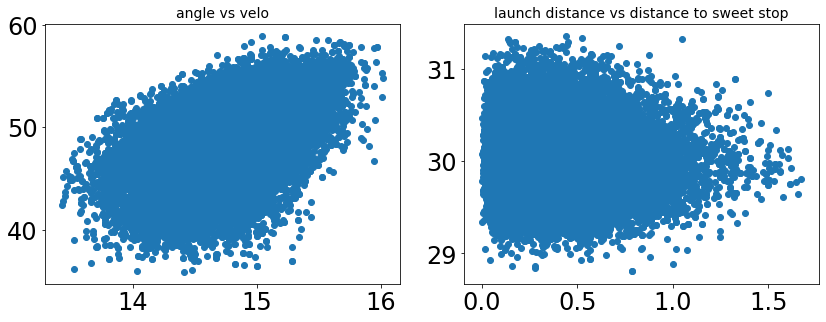

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 1 row, 2 columns

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()

In [51]:
mean = df["launch_angle"].mean(skipna=True)
stdev = df["launch_angle"].std(skipna=True)

mask = (df["launch_angle"] >= mean - k*stdev) & (df["launch_angle"] <= mean + k*stdev)
df = df[mask].copy()

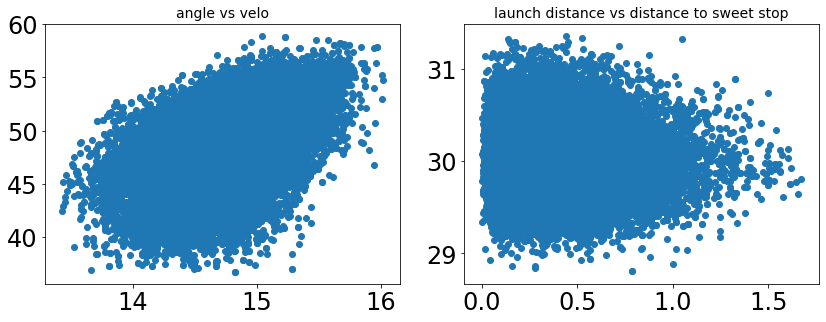

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # 1 row, 2 columns

# First plot
axes[0].scatter(df['release_v_mag'], df['launch_angle'])
axes[0].set_title("angle vs velo", fontsize=14)

# Second plot
axes[1].scatter(df['dist_from_sweet'], df['distance'])
axes[1].set_title("launch distance vs distance to sweet stop", fontsize=14)

plt.tight_layout()
plt.show()

In [53]:
print(f"merged rows: {len(df)}")

merged rows: 49412


In [56]:
for i in df:
    print(i)

ftid
playernamei
personid
shotresult
timeactual
x0
y0
z0
release_v_mag
launch_angle
dist_from_sweet
left_right
short_long
distance


## now with trimmed data, seperate into 23-24 and 24-25 seaons

In [25]:
df["timeactual"] = pd.to_datetime(df["timeactual"], utc=True)

cutoff = pd.Timestamp("2024-08-01", tz="UTC") #seperate the 23-24 and 24-25 season
season_23_24 = df[df["timeactual"] < cutoff].reset_index(drop=True)
season_24_25= df[df["timeactual"] >= cutoff].reset_index(drop=True)

### find summary statistics for each year

In [26]:
c = 250

In [27]:
summary_2324 = build_shooting_summary(season_23_24, c)

In [30]:
summary_2425 = build_shooting_summary(season_24_25, c)

In [33]:
summary_all = build_shooting_summary(df, c)

## velo angle plots for plot 1

In [59]:
players_of_interest = [203081, 201939, 201566, 1628983, 201935, 203497, 1628389, 203507, 203076, 203999]

In [60]:
# Filter your main dataframe (assuming it's called df)
main_characters = df[df['personid'].isin(players_of_interest)].copy()

In [61]:
# Filter first
main_characters = df[df['personid'].isin(players_of_interest)].copy()

# Create a categorical column with the desired order
main_characters['playernamei'] = pd.Categorical(
    main_characters['playernamei'],
    categories=[df.loc[df['personid']==pid, 'playernamei'].iloc[0] for pid in players_of_interest],
    ordered=True
)


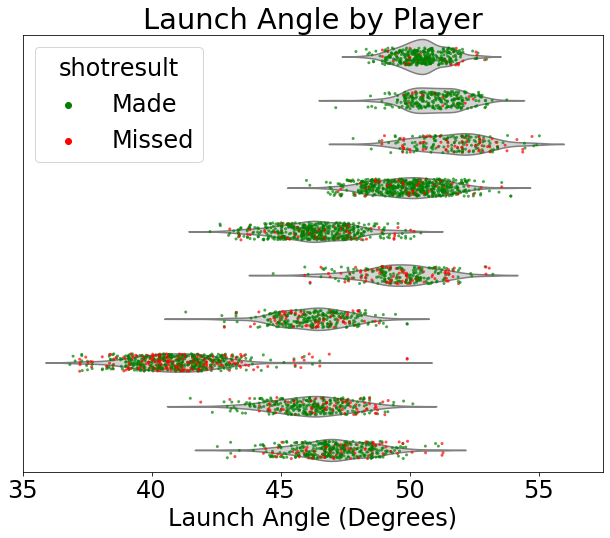

In [63]:
plt.figure(figsize=(9,8))

# Violin plot (distribution)
sns.violinplot(
    x='launch_angle',
    y='playernamei',
    data=main_characters,
    inner=None,
    color='lightgray'
)

# Overlay points using swarmplot instead of stripplot
sns.stripplot(
    x='launch_angle',
    y='playernamei',
    data=main_characters,
    hue='shotresult',
    dodge=False,
    palette={'Made':'green','Missed':'red'},
    size=3,
    alpha=0.7,
    jitter=0.2  # small random horizontal displacement
)

plt.xlim([35,57.5])
plt.xticks([35,40,45,50,55])
plt.yticks([])  # removes all y-axis labels
plt.xlabel('Launch Angle (Degrees)')
plt.ylabel('')
plt.title('Launch Angle by Player')
plt.tight_layout()
#plt.savefig('launch_angles_player.png',dpi=600,pad_inches=0)
plt.show()

## now we can compute statistics for 24-25 season

In [75]:
c=200

In [76]:
summary_all = build_shooting_summary(df, c) #data reloaded as df, trimmed as before with only 24-25 data

In [77]:
print(len(summary_all))

72


In [78]:
np.sum( summary_all['num_shots'] )

21964

### make figure 1 plots, accuracy and precision then command and shooting percentage

In [83]:
players_of_interest = [201566, 203507, 203497, 203999, 1628389, 203076, 201939, 201935, 203081, 1628983]

In [85]:
number_shots = summary_all['num_shots']
shooting_percentages = summary_all['shooting_percentage']
names = summary_all['playernamei']

In [86]:
inaccuracy = summary_all['dist_from_sweet_mean']
variability = summary_all['dist_from_sweet_std']

In [87]:
command = summary_all['command_percentile']

0.9278277822510573


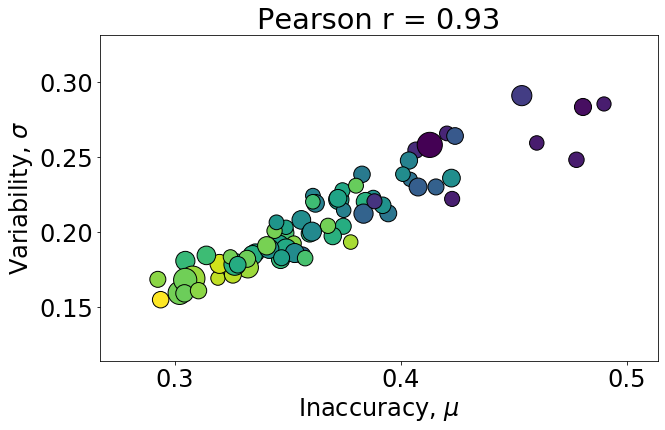

In [88]:
pearson = pearsonr(inaccuracy, variability)[0]
print(pearson)

plt.figure(figsize=(10,6))
plt.scatter(inaccuracy, variability, s=number_shots, c=shooting_percentages, edgecolor='k')
plt.xlabel(r'Inaccuracy, $\mu$')
plt.ylabel(r'Variability, $\sigma$')
plt.yticks([0.15,0.2,0.25,0.3])
plt.xticks([0.3,0.4,0.5])
plt.title(f'Pearson r = {pearson:.2f}')
plt.show()

In [89]:
inaccuracy = 12.0 * inaccuracy
variability = 12.0 * variability

In [90]:
shooting_percentages = 100 * shooting_percentages

In [91]:
plt.figure(figsize=(9,6))
plt.scatter(inaccuracy, variability, s=number_shots, c=shooting_percentages, alpha=0.75)

texts = []
for pid in players_of_interest:
    x = 12.0 * summary_all.loc[summary_all["personid"] == pid, "dist_from_sweet_mean"].iloc[0]
    y = 12.0 * summary_all.loc[summary_all["personid"] == pid, "dist_from_sweet_std"].iloc[0]
    if pid == 203507:
        name = summary_all.loc[summary_all["personid"] == pid, "playernamei"].iloc[0]
        print( name )
        name = 'Player A'
        print( name )
    else:
        name = summary_all.loc[summary_all["personid"] == pid, "playernamei"].iloc[0]
        print( name )
        name = 'Player B'
        print( name )
    plt.annotate(
            name,
            xy=(x, y),                     # point to annotate
            xytext=(x-0.1, y + 0.25),     # where the text sits (offset it!)
            fontsize=16,
            arrowprops=dict(arrowstyle='-', color='gray', lw=1.0),
            bbox=dict(facecolor='white', alpha=0.15, edgecolor='none', boxstyle='round,pad=0.1')
        )

plt.text(3.5, 3.25, f'Pearson $r = ${pearson:.2f}', fontsize=16)

plt.xlabel(r'Inaccuracy, $\mu$ (Inches)')
plt.ylabel(r'Variability, $\sigma$ (Inches)')
plt.yticks([2,2.5,3,3.5])
plt.xticks([3.5,4.5,5.5])
#plt.title(f'Accuracy and Precision in NBA Free Throws')
plt.colorbar(label='Shooting Percentage')
plt.tight_layout()
#plt.savefig('command_fig2_anonymized.png',dpi=600,pad_inches=0)
plt.show()

In [ ]:
pearson = pearsonr(shooting_percentages, command)[0]
print(pearson)

plt.figure(figsize=(8,6))
plt.scatter(shooting_percentages, command, s=number_shots, alpha=0.75)

texts = []
for pid in players_of_interest:
    x = 100 * summary_all.loc[summary_all["personid"] == pid, "shooting_percentage"].iloc[0]
    y = summary_all.loc[summary_all["personid"] == pid, "command_percentile"].iloc[0]
    if pid == 203507:
        name = summary_all.loc[summary_all["personid"] == pid, "playernamei"].iloc[0]
        print( name )
        name = 'Player A'
        print( name )
        plt.annotate(
            name,
            xy=(x, y),                     # point to annotate
            xytext=(x-0.1, y + 0.25),     # where the text sits (offset it!)
            fontsize=16,
            arrowprops=dict(arrowstyle='-', color='gray', lw=1.0),
            bbox=dict(facecolor='white', alpha=0.15, edgecolor='none', boxstyle='round,pad=0.1')
        )
    else:
        name = summary_all.loc[summary_all["personid"] == pid, "playernamei"].iloc[0]
        print( name )
        name = 'Player B'
        print( name )
        plt.annotate(
            name,
            xy=(x, y),                     # point to annotate
            xytext=(x-0.1, y - 0.25),     # where the text sits (offset it!)
            fontsize=16,
            arrowprops=dict(arrowstyle='-', color='gray', lw=1.0),
            bbox=dict(facecolor='white', alpha=0.15, edgecolor='none', boxstyle='round,pad=0.1')
        )

plt.text(85,0.1,f'Pearson $r = ${pearson:.2f}', fontsize=16)

plt.xlabel(r'Shooting Percentage')
plt.ylabel(r'Normalized Command')
#plt.title(f'Pearson r = {pearson:.2f}')
plt.xticks([60,70,80,90,100])
plt.tight_layout()
plt.ylim([-0.1,1.1])
plt.tight_layout()
#plt.savefig('command_fig3_anonymized.png',dpi=600,pad_inches=0)
plt.show()

### make figure 4 plots, command and consistency then command and each element of consistency

In [94]:
consistency = summary_all['consistency_score_percentile']

In [95]:
m, b = np.polyfit(consistency, command, 1)

x_fit = np.linspace(0,1)
y_fit = m * x_fit + b

In [ ]:
pearson = pearsonr(consistency, command)[0]
print(pearson)

plt.figure(figsize=(10,6))
plt.plot(x_fit, y_fit, 'k--', zorder=0)
plt.scatter(consistency, command, s=number_shots, c=shooting_percentages, alpha=0.75)

texts = []
for pid in players_of_interest:
    x = summary_all.loc[summary_all["personid"] == pid, "consistency_score_percentile"].iloc[0]
    y = summary_all.loc[summary_all["personid"] == pid, "command_percentile"].iloc[0]
    if pid == 203507:
        name = summary_all.loc[summary_all["personid"] == pid, "playernamei"].iloc[0]
        print( name )
        name = 'Player A'
        print( name )
        plt.annotate(
            name,
            xy=(x, y),                     # point to annotate
            xytext=(x-0.1, y + 0.15),     # where the text sits (offset it!)
            fontsize=16,
            arrowprops=dict(arrowstyle='-', color='gray', lw=1.0),
            bbox=dict(facecolor='white', alpha=0.15, edgecolor='none', boxstyle='round,pad=0.1')
        )
    else:
        name = summary_all.loc[summary_all["personid"] == pid, "playernamei"].iloc[0]
        print( name )
        name = 'Player B'
        print( name )
        plt.annotate(
            name,
            xy=(x, y),                     # point to annotate
            xytext=(x, y - 0.3),     # where the text sits (offset it!)
            fontsize=16,
            arrowprops=dict(arrowstyle='-', color='gray', lw=1.0),
            bbox=dict(facecolor='white', alpha=0.15, edgecolor='none', boxstyle='round,pad=0.1')
        )

plt.text(0.75, 0.1, f'Pearson $r = ${pearson:.2f}', fontsize=16)

plt.xlabel(r'Normalized Touch')
plt.ylabel(r'Normalized Command')
#plt.title(f'Touch at release drives command')
plt.tight_layout()
#plt.savefig('command_fig5_anonymized_large.png',dpi=600,pad_inches=0)
plt.show()

In [106]:
velo_cons = summary_all['launch_velo_consistency_normalized']
angle_cons = summary_all['launch_angle_consistency_normalized']
distance_cons = summary_all['launch_distance_consistency_normalized']

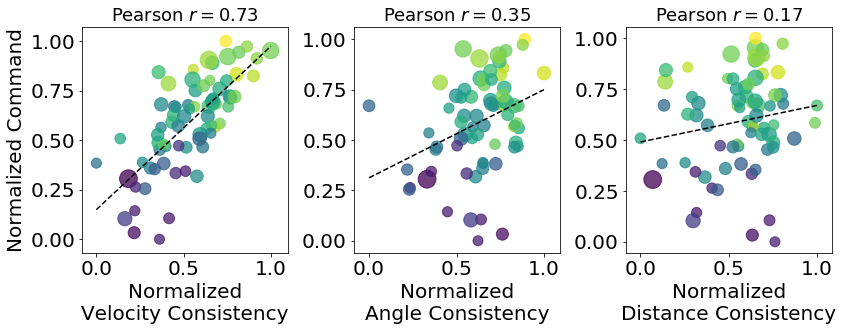

In [111]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
# left plot
m, b = np.polyfit(velo_cons, command, 1)
x_fit = np.linspace(0,1)
y_fit = m * x_fit + b
axes[0].plot(x_fit, y_fit, 'k--')

axes[0].scatter(velo_cons, command, s=number_shots/2, c=shooting_percentages,alpha=0.75)#, s = summary_2425_season['num_shots']/4, c = summary_2425_season['shooting_percentage'])
pearson = pearsonr(velo_cons, command)[0]
axes[0].set_title(f'Pearson $r = ${pearson:.2f}', fontsize=18)
axes[0].set_xlabel('Normalized\nVelocity Consistency')
axes[0].set_ylabel('Normalized Command')
#axes[0].set_xticks([0,25,50,75,100])

# middle plot
m, b = np.polyfit(angle_cons, command, 1)
x_fit = np.linspace(0,1)
y_fit = m * x_fit + b
axes[1].plot(x_fit, y_fit, 'k--')

axes[1].scatter(angle_cons, command, s=number_shots/2, c=shooting_percentages,alpha=0.75)#, s = summary_2425_season['num_shots']/4, c = summary_2425_season['shooting_percentage'])
pearson = pearsonr(angle_cons, command)[0]
axes[1].set_title(f'Pearson $r = ${pearson:.2f}', fontsize=18)
axes[1].set_xlabel('Normalized\nAngle Consistency')
#axes[1].set_xticks([0,25,50,75,100])


# right plot
m, b = np.polyfit(distance_cons, command, 1)
x_fit = np.linspace(0,1)
y_fit = m * x_fit + b
axes[2].plot(x_fit, y_fit, 'k--')

axes[2].scatter(distance_cons, command, s=number_shots/2, c=shooting_percentages,alpha=0.75)#, s = summary_2425_season['num_shots']/4, c = summary_2425_season['shooting_percentage'])
pearson = pearsonr(distance_cons, command)[0]
axes[2].set_title(f'Pearson $r = ${pearson:.2f}', fontsize=18)
axes[2].set_xlabel('Normalized\nDistance Consistency')
#axes[2].set_xticks([0,25,50,75,100])

plt.tight_layout()
#plt.savefig('consistency_components.png',dpi=600,pad_inches=0)

plt.show()

In [113]:
cols = [
    'personid',
    'playernamei',
    'num_shots',
    'launch_velo_consistency_normalized',
    'launch_angle_consistency_normalized',
    'launch_distance_consistency_normalized',
    'consistency_score_percentile',
    'shooting_percentage',
    'command_percentile'
]

summary_percentiles = summary_all[cols].copy()

In [114]:
summary_percentiles = summary_all[['personid','playernamei','num_shots']].copy()

summary_percentiles['launch_velo_consistency_percentile'] = 100 * (
    summary_all['launch_velo_consistency_normalized'].rank(pct=True)
)

summary_percentiles['launch_angle_consistency_percentile'] = 100 * (
    summary_all['launch_angle_consistency_normalized'].rank(pct=True)
)

summary_percentiles['launch_distance_consistency_percentile'] = 100 * (
    summary_all['launch_distance_consistency_normalized'].rank(pct=True)
)

summary_percentiles['consistency_score_percentile'] = 100 * (
    summary_all['consistency_score_percentile'].rank(pct=True)
)

summary_percentiles['command_percentile'] = 100 * (
    summary_all['command_percentile'].rank(pct=True)
)

summary_percentiles['shooting_percentage_percentile'] = 100 * (
    summary_all['shooting_percentage'].rank(pct=True)
)

In [115]:
#summary_percentiles.to_csv("refined_2425_foulshotdata_percentiles.csv", index=False)

In [127]:
players_of_interest = [201939, 203081, 201935, 203076, 1628389, 201566, 203507]

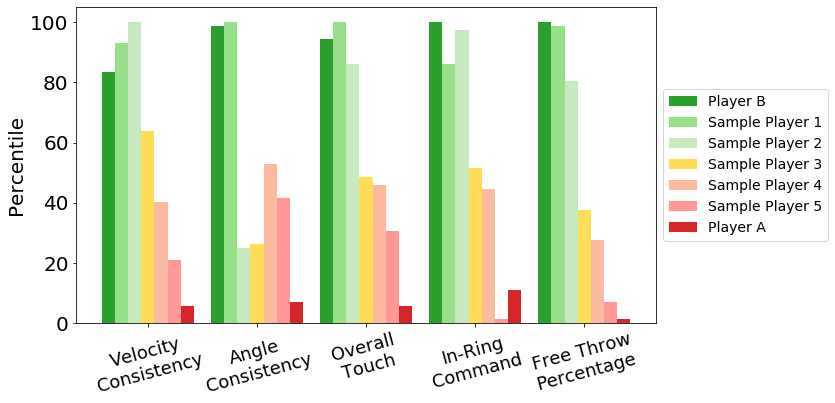

In [133]:
# Filter summary for the selected players
plot_df = summary_percentiles[summary_percentiles['personid'].isin(players_of_interest)]

# Metrics and labels
metrics = [
    'launch_velo_consistency_percentile',
    'launch_angle_consistency_percentile',
    'consistency_score_percentile',
    'command_percentile',
    'shooting_percentage_percentile'
]
metric_labels = [
    'Velocity\nConsistency',
    'Angle\nConsistency',
    'Overall\nTouch',
    'In-Ring\nCommand',
    'Free Throw\nPercentage'
]

# Custom colors (green to red)
colors = ['#2ca02c', '#98df8a', '#c7e9c0', '#ffdd57', '#fcbba1', '#ff9896', '#d62728']

# Custom legend labels (Player B → samples → Player A)
custom_labels = ["Player B"] + [f"Sample Player {i}" for i in range(1, 6)] + ["Player A"]

# Plotting setup
x = np.arange(len(metrics))
bar_width = 0.12

fig, ax = plt.subplots(figsize=(12, 6))

# Plot each player
for idx, (player_id, color, label) in enumerate(zip(players_of_interest, colors, custom_labels)):
    row = plot_df[plot_df['personid'] == player_id]
    if not row.empty:
        values = row[metrics].values[0]
        offset = (idx - len(players_of_interest) // 2) * bar_width
        ax.bar(x + offset, values, width=bar_width, label=label, color=color)

# Formatting
ax.set_xticks(x)
ax.set_xticklabels(metric_labels, rotation=15, fontsize=18)
ax.set_ylabel('Percentile')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=14)
ax.set_ylim([0, 105])

plt.tight_layout()
#plt.savefig('command_fig6_anonymized.png',dpi=600,pad_inches=0)
plt.show()